# Overview

This notebook was put together and presented by Beau Leblond, TA for one of Prince's sections of DS6021. I'll be adding some commentary and adaptations along the way.

In this example, we will use the `framingham` dataset to look at missing data and different ways to handle it. The Framingham Heart Study Dataset includes over 4,240 records, 16 columns, and 15 attributes. The goal of the dataset is to predict whether the patient has 10-year risk of future (CHD) coronary heart disease, and we have used it in our notebooks to learn about Logistic Regression. 

For the example in this notebook, we will predict total cholesterol instead of CHD. (e.g. We'll be doing a linear regression instead of a logistic one.)

We will be looking at what happens when data goes missing, how it impacts model predictions, and ways we can do imputation. 

## Get the data

In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [2]:
# Read in the framingham dataset and explore missing data. 

framingham = pd.read_csv("C:\\Users\\witze\\Downloads\\DS6021_F26\\data\\framingham.csv", na_values='').dropna().reset_index(drop=True)
print(framingham.isna().sum())
print("-----------------------")
print(framingham.shape)

male               0
age                0
education          0
currentSmoker      0
cigsPerDay         0
BPMeds             0
prevalentStroke    0
prevalentHyp       0
diabetes           0
totChol            0
sysBP              0
diaBP              0
BMI                0
heartRate          0
glucose            0
TenYearCHD         0
dtype: int64
-----------------------
(3658, 16)


## Exploring features of interest

Numeric variables we want to explore: `age`, `cigsPerDay`, `totChol`, `sysBP`, `BMI`

We will use `totChol` as the target variable

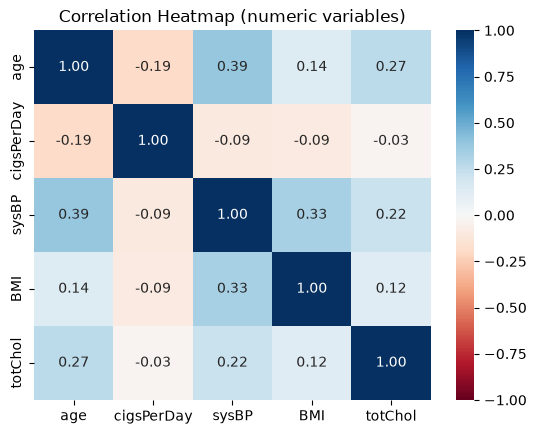

In [3]:
#Let's first look at the correlation across all of these numeric variables
num_cols = ['age', 'cigsPerDay', 'sysBP', 'BMI', 'totChol']
corr = framingham[num_cols].corr()

sns.heatmap(
    corr, annot=True, fmt=".2f",
    cmap="RdBu", vmin=-1, vmax=1
)
plt.title("Correlation Heatmap (numeric variables)")
plt.show()

## Predicting total cholesterol with different amounts of missing data

In [4]:
# Let's predict total cholesterol -- This cell is going to error!

predictors = ['age', 'cigsPerDay', 'sysBP', 'BMI']
framingham_cc = framingham[predictors + ['totChol']]

X = framingham_cc[predictors]
y = framingham_cc['totChol']

model1_sk = LinearRegression().fit(X, y)

print(model1_sk.intercept_)
print(dict(zip(predictors, model1_sk.coef_)))
print(model1_sk.score(X, y))  # R^2

133.29912528534894
{'age': np.float64(1.131197506269368), 'cigsPerDay': np.float64(0.10057725223543769), 'sysBP': np.float64(0.23849789552440037), 'BMI': np.float64(0.5824705119176009)}
0.0908624126246742


## Approach #1: Drop all rows with any missing values from the original dataset

In [5]:
# Sklearn does not automatically handle missing predictors. This is a good thing from a software engineering perspective. 
# You don't want functions to secretly do calculations that your users are not aware of. 
# In order to use sklearn, we either need to drop them or determine an imputation technique


# Let's try a few approaches - first, we will simply drop all of the NA values
predictors = ['age', 'cigsPerDay', 'sysBP', 'BMI']
framingham_cc = framingham[predictors + ['totChol']].dropna()

X = framingham_cc[predictors]
y = framingham_cc['totChol']

model1_sk = LinearRegression().fit(X, y)

print(f"Number of rows: {framingham_cc.shape[0]:,}  |  Columns: {framingham_cc.shape[1]}")
print(f"Intercept: {model1_sk.intercept_:.4f}")
print("Coefficients:")
for name, coef in zip(predictors, model1_sk.coef_):
    print(f"  {name:<12} {coef:>10.4f}")
print(f"R²: {model1_sk.score(X, y):.4f}")

Number of rows: 3,658  |  Columns: 5
Intercept: 133.2991
Coefficients:
  age              1.1312
  cigsPerDay       0.1006
  sysBP            0.2385
  BMI              0.5825
R²: 0.0909


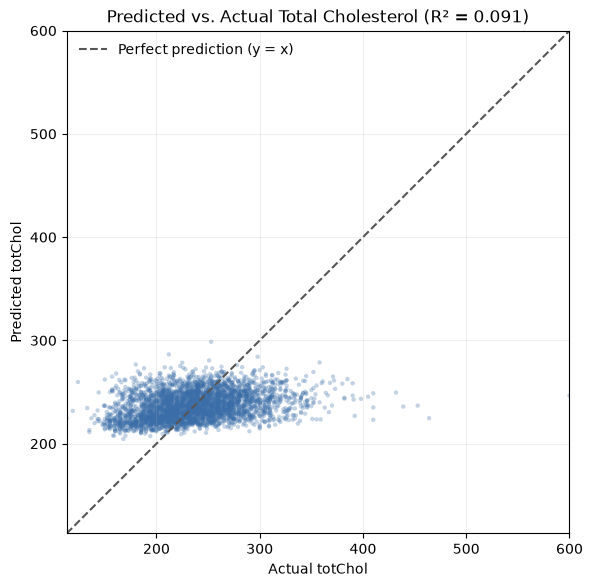

In [6]:
# Let's plot actual vs predicted to explore why our R2 value is so bad. 
y_pred = model1_sk.predict(X)
r2 = model1_sk.score(X, y)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y, y_pred, s=10, alpha=0.3, color="#3b6ea8", edgecolor="none")

# y = x reference line: perfect predictions would fall on it
lims = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
ax.plot(lims, lims, color="#555555", linewidth=1.5, linestyle="--", label="Perfect prediction (y = x)")

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect("equal")
ax.set_xlabel("Actual totChol")
ax.set_ylabel("Predicted totChol")
ax.set_title(f"Predicted vs. Actual Total Cholesterol (R² = {r2:.3f})")
ax.grid(alpha=0.2)
ax.legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

## Approach #2: Manually remove 80% of the remaining blood pressure values and see what happens

Note that we will keep Approach #1 (the original dataset with the missing values dropped) as our "base" dataset for the rest of this lab. 

In [7]:
## Randomly delete 80% of blood pressure data

# First we'll make a copy of the original data frame
missing_framingham = framingham.copy()

# In this new data frame, let's randomly delete 80% of the values for sysBP
# We are choosing a random seed so the results are repeatable. 
missing_framingham.loc[missing_framingham.sample(frac=0.8, random_state=567).index, 'sysBP'] = np.nan

Below, we will fit the model again, but this time we will use statsmodels, which handles missing values automatically. 

In [8]:
# First let's fit the models and look at how much data was used in each case. 

model1 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=framingham).fit()
model2 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=missing_framingham).fit()

print(f"Number of observations used in model 1: {model1.nobs}")
print(f"Number of observations used in model 2: {model2.nobs}")


Number of observations used in model 1: 3658.0
Number of observations used in model 2: 732.0


From the output above, we can see that ```smf.ols``` silently dropped the missing data, and model 2 has about 20% of the data of model 1, which aligns with us dropping 80% of the values. 

Now, let's compare the coefficients. Note that model1 should give the same values as our sklearn model for the same number of observations. We will consider Model 1 as our baseline, since we deleted the smallest amount of data, and did not have to impute anything. 

In [9]:
models = {"model1 (framingham)": model1, "model2 (missing_framingham)": model2}

comparison = pd.DataFrame({
    label: pd.concat([m.params, pd.Series({"R²": m.rsquared, "Rows used": m.nobs})])
    for label, m in models.items()
})

formatted = comparison.map("{:.4f}".format)
formatted.loc["Rows used"] = comparison.loc["Rows used"].map("{:,.0f}".format)
formatted

,model1 (framingham),model2 (missing_framingham)
Intercept,133.2991,117.7938
age,1.1312,1.3319
cigsPerDay,0.1006,-0.0041
sysBP,0.2385,0.3952
BMI,0.5825,0.0169
R²,0.0909,0.1534
Rows used,"3,658",732


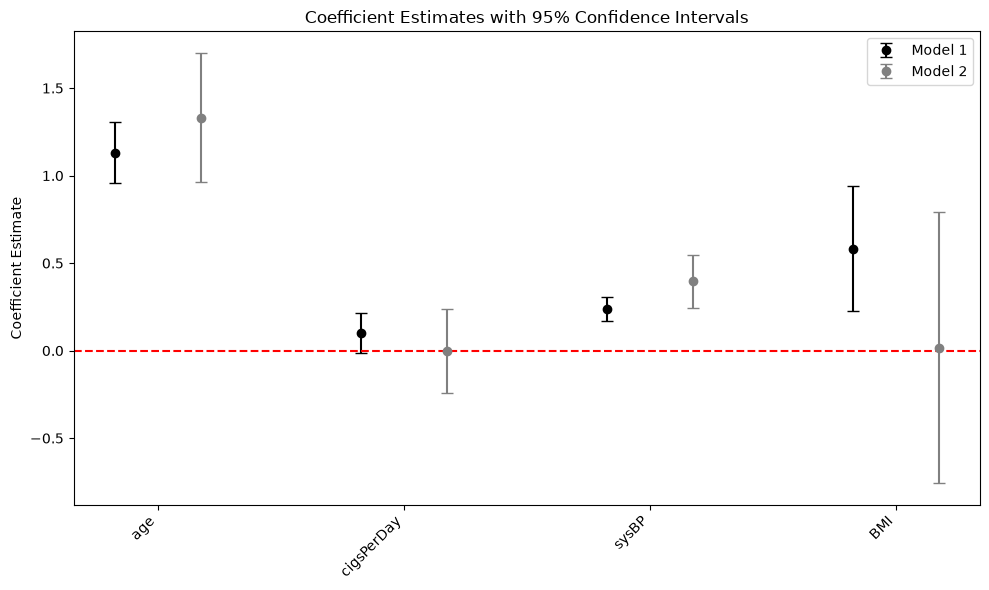

In [10]:
# Now, lets plot the confidence intervals for each of the coefficients.
# We want to look at how they change when we have only a fraction of the data 

def coef_table(model):
    """Coefficients and 95% CIs, without the intercept."""
    table = model.conf_int().drop("Intercept")
    table.columns = ["lower", "upper"]
    table["coef"] = model.params.drop("Intercept")
    return table

models = {"Model 1": (model1, "black"), "Model 2": (model2, "gray")}
tables = {name: coef_table(m) for name, (m, _) in models.items()}
common_vars = tables["Model 1"].index.intersection(tables["Model 2"].index)

x = np.arange(len(common_vars))
width = 0.35  # spacing between bars

plt.figure(figsize=(10, 6))
for offset, (name, (_, color)) in zip([-width/2, width/2], models.items()):
    t = tables[name].loc[common_vars]
    plt.errorbar(
        x + offset, t["coef"],
        yerr=[t["coef"] - t["lower"], t["upper"] - t["coef"]],
        fmt='o', color=color, ecolor=color, capsize=4, label=name
    )

plt.axhline(0, color='red', linestyle='--')
plt.xticks(x, common_vars, rotation=45, ha='right')
plt.ylabel('Coefficient Estimate')
plt.title('Coefficient Estimates with 95% Confidence Intervals')
plt.legend()
plt.tight_layout()
plt.show()

### Questions to consider

What happened when we fit the model again? Why are the confidence intervals different for our parameters?

Is the blood pressure variable now missing completely at random, missing at random, or missing not at random? Why?

## Approach #3: Use mean imputation on the missing data

Now let's take the missing values and impute the mean BP value for each of them. Then, let's refit the model and note the differences in fit and coefficient estimates.

Note: In the cell below are using the mean values from the missing dataset. Why might we be doing this instead of using the mean values from the full dataset? 

In [11]:
# First, make a copy of the missing dataset
mean_framingham  = missing_framingham.copy()

# Calculate the mean sysBP and impute that for the missing values
mean_sysBP = mean_framingham['sysBP'].mean(skipna=True)
mean_framingham['sysBP'] = mean_framingham['sysBP'].fillna(mean_sysBP)

model3 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=mean_framingham).fit()


In [12]:
# Now let's compare results with models 1 and 2 above
models = {"model1 (framingham)": model1, "model2 (missing_framingham)": model2,
          "model3 (mean imputation)": model3}

comparison = pd.DataFrame({
    label: pd.concat([m.params, pd.Series({"R²": m.rsquared, "Rows used": m.nobs})])
    for label, m in models.items()
})

formatted = comparison.map("{:.4f}".format)
formatted.loc["Rows used"] = comparison.loc["Rows used"].map("{:,.0f}".format)
formatted

,model1 (framingham),model2 (missing_framingham),model3 (mean imputation)
Intercept,133.2991,117.7938,102.5446
age,1.1312,1.3319,1.2824
cigsPerDay,0.1006,-0.0041,0.1044
sysBP,0.2385,0.3952,0.3624
BMI,0.5825,0.0169,0.8527
R²,0.0909,0.1534,0.0857
Rows used,"3,658",732,"3,658"


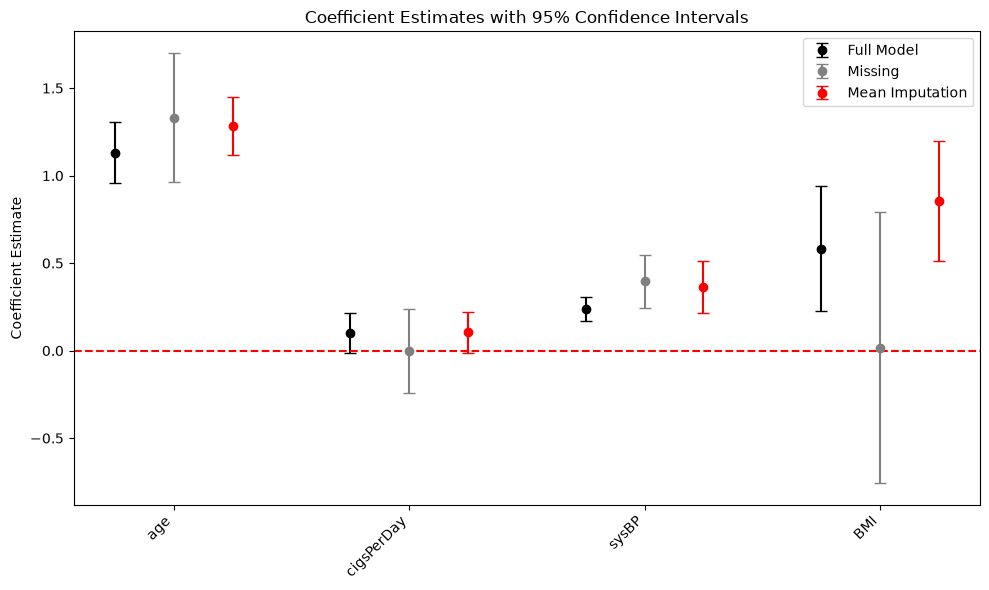

In [13]:
models = {
    "Full Model": (model1, "black"),
    "Missing": (model2, "gray"),
    "Mean Imputation": (model3, "red"),
}
tables = {name: coef_table(m) for name, (m, _) in models.items()}

common_vars = tables["Full Model"].index
for t in tables.values():
    common_vars = common_vars.intersection(t.index)

x = np.arange(len(common_vars))
width = 0.25  # spacing between bars
offsets = (np.arange(len(models)) - (len(models) - 1) / 2) * width  # -width, 0, +width

plt.figure(figsize=(10, 6))
for offset, (name, (_, color)) in zip(offsets, models.items()):
    t = tables[name].loc[common_vars]
    plt.errorbar(
        x + offset, t["coef"],
        yerr=[t["coef"] - t["lower"], t["upper"] - t["coef"]],
        fmt='o', color=color, ecolor=color, capsize=4, label=name
    )

plt.axhline(0, color='red', linestyle='--')
plt.xticks(x, common_vars, rotation=45, ha='right')
plt.ylabel('Coefficient Estimate')
plt.title('Coefficient Estimates with 95% Confidence Intervals')
plt.legend()
plt.tight_layout()
plt.show()

## Approach #4: Impute sysBP using other data in the dataset

Now, instead of using mean imputation, predict sysBP from age, cigsPerDay, and BMI and see how we do. 

In [14]:
# Using the observed data, predict sysBP from age, cigsPerDay, and BMI
observed = missing_framingham[missing_framingham['sysBP'].notna()]
missing = missing_framingham[missing_framingham['sysBP'].isna()]

formula = "sysBP ~ age + cigsPerDay + BMI"
formula2 = "sysBP ~ age + cigsPerDay + BMI + totChol"

imputer_model = smf.ols(formula, data=observed).fit()
imputer_model2 = smf.ols(formula2, data=observed).fit()

In [15]:
# Now, predict missing values for sysBP using the imputer_model
predicted = imputer_model.predict(missing)
predicted2 = imputer_model2.predict(missing)

#Add residual noise to preserve variance
residual_std = np.std(imputer_model.resid)
noise_seed = 234
rng = np.random.default_rng(noise_seed)
imputed_values = predicted + rng.normal(0, residual_std, size=len(predicted))

residual_std2 = np.std(imputer_model2.resid)
rng2 = np.random.default_rng(noise_seed)
imputed_values2 = predicted2 + rng2.normal(0, residual_std2, size=len(predicted2))

#Fill missing values
reg2_framingham = missing_framingham.copy()   
missing_framingham.loc[missing.index, 'sysBP'] = imputed_values
reg2_framingham.loc[missing.index, 'sysBP'] = imputed_values2

In [16]:
# Now let's predict total cholesterol using our predicted values of sysBP
model4 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=missing_framingham).fit()
model5 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=reg2_framingham).fit()

# Compare with the other models
models = {"model1 (framingham)": model1, "model2 (missing_framingham)": model2,
          "model3 (mean imputation)": model3, "model4 (regression imputation)": model4,
          "model5 (regression imputation with totChol)": model5}

comparison = pd.DataFrame({
    label: pd.concat([m.params, pd.Series({"R²": m.rsquared, "Rows used": m.nobs})])
    for label, m in models.items()
})

formatted = comparison.map("{:.4f}".format)
formatted.loc["Rows used"] = comparison.loc["Rows used"].map("{:,.0f}".format)
formatted

,model1 (framingham),model2 (missing_framingham),model3 (mean imputation),model4 (regression imputation),model5 (regression imputation with totChol)
Intercept,133.2991,117.7938,102.5446,139.1412,119.7411
age,1.1312,1.3319,1.2824,1.2501,0.9416
cigsPerDay,0.1006,-0.0041,0.1044,0.1048,0.1197
sysBP,0.2385,0.3952,0.3624,0.1085,0.4746
BMI,0.5825,0.0169,0.8527,0.7953,0.2617
R²,0.0909,0.1534,0.0857,0.0820,0.1212
Rows used,"3,658",732,"3,658","3,658","3,658"


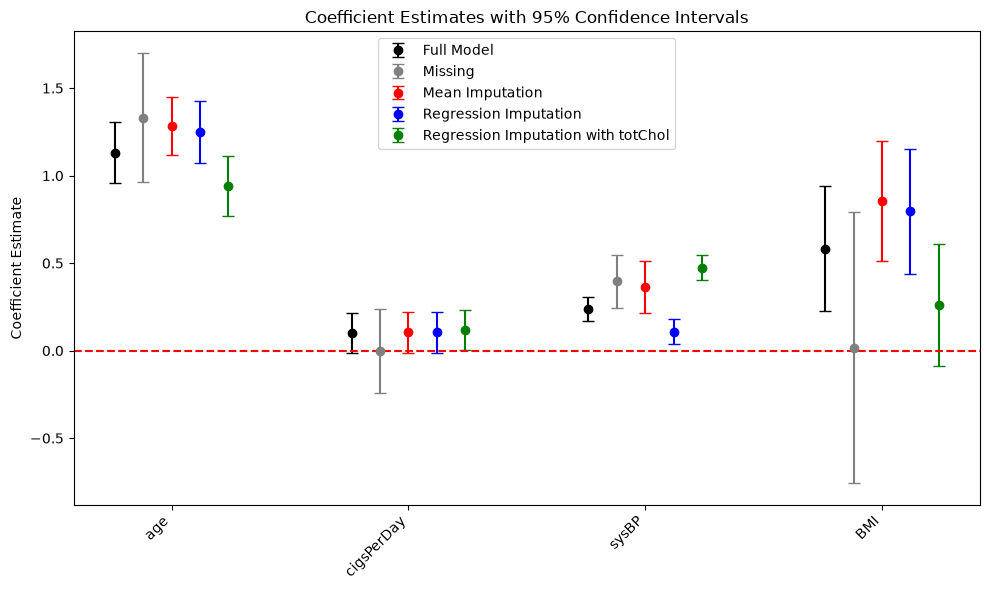

In [17]:
models = {
    "Full Model": (model1, "black"),
    "Missing": (model2, "gray"),
    "Mean Imputation": (model3, "red"),
    "Regression Imputation": (model4, "blue"),
    "Regression Imputation with totChol": (model5, "green"),
}
tables = {name: coef_table(m) for name, (m, _) in models.items()}

common_vars = tables["Full Model"].index
for t in tables.values():
    common_vars = common_vars.intersection(t.index)

x = np.arange(len(common_vars))
width = 0.6/len(models)  # spacing between bars
offsets = (np.arange(len(models)) - (len(models) - 1) / 2) * width  # -width, 0, +width

plt.figure(figsize=(10, 6))
for offset, (name, (_, color)) in zip(offsets, models.items()):
    t = tables[name].loc[common_vars]
    plt.errorbar(
        x + offset, t["coef"],
        yerr=[t["coef"] - t["lower"], t["upper"] - t["coef"]],
        fmt='o', color=color, ecolor=color, capsize=4, label=name
    )

plt.axhline(0, color='red', linestyle='--')
plt.xticks(x, common_vars, rotation=45, ha='right')
plt.ylabel('Coefficient Estimate')
plt.title('Coefficient Estimates with 95% Confidence Intervals')
plt.legend()
plt.tight_layout()
plt.show()

# My work

### AI Note: Code assisted with generative AI will have a comment with it. 

### My second notebook is also in the github named "LabActivity07-2"

1a: I changed the seed from 123 to 234. 

sysBP	0.2385	0.3952	0.3624	0.0930

sysBP	0.2385	0.3952	0.3624	0.1085

- As we change the noise seed, the coefficient estimate for sysBP does change. This is because approach 4 uses randomization to fill in missing data based on the data that's already been recorded. Seeing a change like this shows that the initial random noise can't be trusted on its own, and that this process needs to be repeated. 

The imputation with totChol as a predictor has a significantly higher coefficient prediction for sysBP and a notably lower coefficient prediction for both age and BMI. Compared to the full model, whatever difference the first regression imputation has with the full mode, this difference goes the opposite way with totChol as an additional predictor, meaning Model5 may overestimate when model4 underestimates. Model 5 also has a higher R^2 and lower intercept than model 4. 